
# Classification of text documents using sparse features

This is an example showing how scikit-learn can be used to classify documents by
topics using a [Bag of Words approach](https://en.wikipedia.org/wiki/Bag-of-words_model). This example uses a
Tf-idf-weighted document-term sparse matrix to encode the features and
demonstrates various classifiers that can efficiently handle sparse matrices.

For document analysis via an unsupervised learning approach, see the example
script `sphx_glr_auto_examples_text_plot_document_clustering.py`.


In [1]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

## Loading and vectorizing the 20 newsgroups text dataset

We define a function to load data from `20newsgroups_dataset`, which
comprises around 18,000 newsgroups posts on 20 topics split in two subsets:
one for training (or development) and the other one for testing (or for
performance evaluation). Note that, by default, the text samples contain some
message metadata such as `'headers'`, `'footers'` (signatures) and `'quotes'`
to other posts. The `fetch_20newsgroups` function therefore accepts a
parameter named `remove` to attempt stripping such information that can make
the classification problem "too easy". This is achieved using simple
heuristics that are neither perfect nor standard, hence disabled by default.



In [2]:
from time import time

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

categories = [
    "alt.atheism",
    "talk.religion.misc",
    "comp.graphics",
    "sci.space",
]


def size_mb(docs):
    return sum(len(s.encode("utf-8")) for s in docs) / 1e6


def load_dataset(verbose=False, remove=()):
    """Load and vectorize the 20 newsgroups dataset."""

    data_train = fetch_20newsgroups(
        subset="train",
        categories=categories,
        shuffle=True,
        random_state=42,
        remove=remove,
    )

    data_test = fetch_20newsgroups(
        subset="test",
        categories=categories,
        shuffle=True,
        random_state=42,
        remove=remove,
    )

    # order of labels in `target_names` can be different from `categories`
    target_names = data_train.target_names

    # split target in a training set and a test set
    y_train, y_test = data_train.target, data_test.target

    # Extracting features from the training data using a sparse vectorizer
    t0 = time()
    vectorizer = TfidfVectorizer(
        sublinear_tf=True, max_df=0.5, min_df=5, stop_words="english"
    )
    X_train = vectorizer.fit_transform(data_train.data)
    duration_train = time() - t0

    # Extracting features from the test data using the same vectorizer
    t0 = time()
    X_test = vectorizer.transform(data_test.data)
    duration_test = time() - t0

    feature_names = vectorizer.get_feature_names_out()

    if verbose:
        # compute size of loaded data
        data_train_size_mb = size_mb(data_train.data)
        data_test_size_mb = size_mb(data_test.data)

        print(
            f"{len(data_train.data)} documents - "
            f"{data_train_size_mb:.2f}MB (training set)"
        )
        print(f"{len(data_test.data)} documents - {data_test_size_mb:.2f}MB (test set)")
        print(f"{len(target_names)} categories")
        print(
            f"vectorize training done in {duration_train:.3f}s "
            f"at {data_train_size_mb / duration_train:.3f}MB/s"
        )
        print(f"n_samples: {X_train.shape[0]}, n_features: {X_train.shape[1]}")
        print(
            f"vectorize testing done in {duration_test:.3f}s "
            f"at {data_test_size_mb / duration_test:.3f}MB/s"
        )
        print(f"n_samples: {X_test.shape[0]}, n_features: {X_test.shape[1]}")

    return X_train, X_test, y_train, y_test, feature_names, target_names

## Analysis of a bag-of-words document classifier

We will now train a classifier twice, once on the text samples including
metadata and once after stripping the metadata. For both cases we will analyze
the classification errors on a test set using a confusion matrix and inspect
the coefficients that define the classification function of the trained
models.

### Model without metadata stripping

We start by using the custom function `load_dataset` to load the data without
metadata stripping.



In [3]:
X_train, X_test, y_train, y_test, feature_names, target_names = load_dataset(
    verbose=True
)

2034 documents - 3.98MB (training set)
1353 documents - 2.87MB (test set)
4 categories
vectorize training done in 0.370s at 10.752MB/s
n_samples: 2034, n_features: 7831
vectorize testing done in 0.218s at 13.151MB/s
n_samples: 1353, n_features: 7831


Our first model is an instance of the
:class:`~sklearn.linear_model.RidgeClassifier` class. This is a linear
classification model that uses the mean squared error on {-1, 1} encoded
targets, one for each possible class. Contrary to
:class:`~sklearn.linear_model.LogisticRegression`,
:class:`~sklearn.linear_model.RidgeClassifier` does not
provide probabilistic predictions (no `predict_proba` method),
but it is often faster to train.



In [4]:
from sklearn.linear_model import RidgeClassifier

clf = RidgeClassifier(tol=1e-2, solver="sparse_cg")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

We plot the confusion matrix of this classifier to find if there is a pattern
in the classification errors.



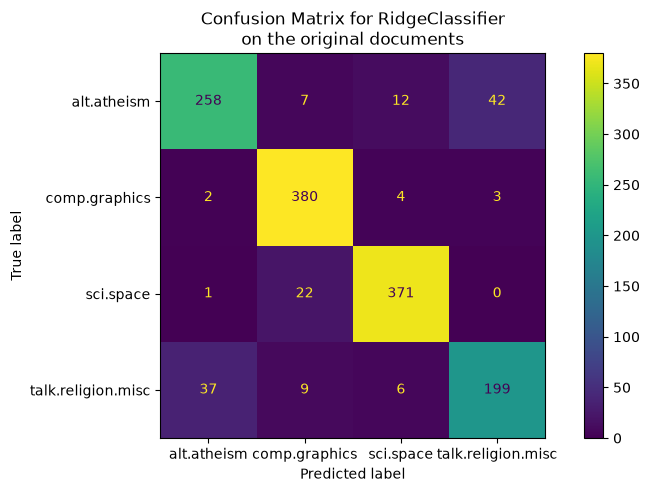

In [5]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(
    f"Confusion Matrix for {clf.__class__.__name__}\non the original documents"
)

The confusion matrix highlights that documents of the `alt.atheism` class are
often confused with documents with the class `talk.religion.misc` class and
vice-versa which is expected since the topics are semantically related.

We also observe that some documents of the `sci.space` class can be misclassified as
`comp.graphics` while the converse is much rarer. A manual inspection of those
badly classified documents would be required to get some insights on this
asymmetry. It could be the case that the vocabulary of the space topic could
be more specific than the vocabulary for computer graphics.

We can gain a deeper understanding of how this classifier makes its decisions
by looking at the words with the highest average feature effects:



top 5 keywords per class:
  alt.atheism comp.graphics sci.space talk.religion.misc
0       keith      graphics     space          christian
1         god    university      nasa                com
2    atheists        thanks     orbit                god
3      people          does      moon           morality
4     caltech         image    access             people


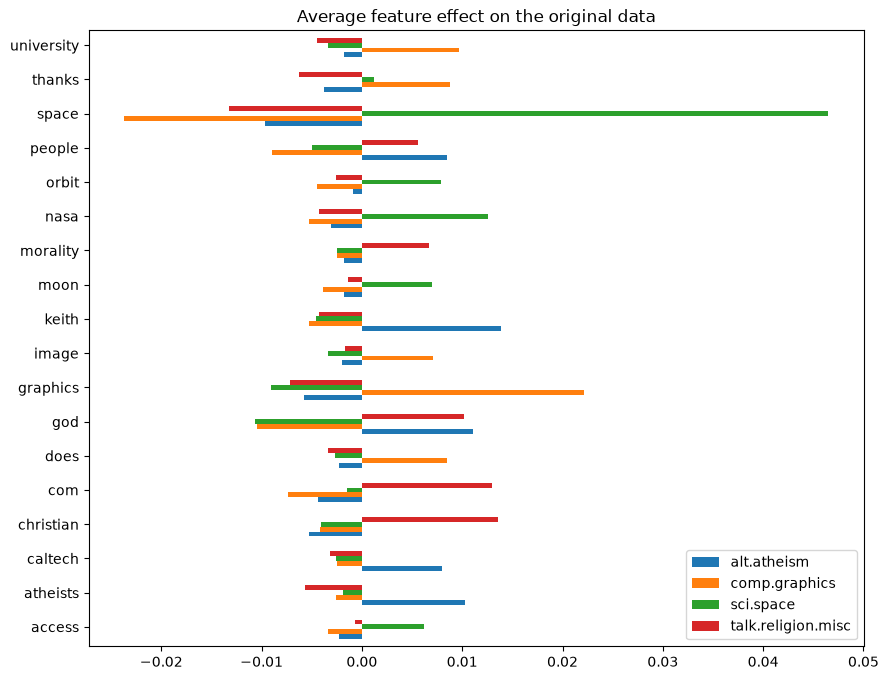

In [6]:
import numpy as np
import pandas as pd


def plot_feature_effects():
    # learned coefficients weighted by frequency of appearance
    average_feature_effects = clf.coef_ * np.asarray(X_train.mean(axis=0)).ravel()

    for i, label in enumerate(target_names):
        top5 = np.argsort(average_feature_effects[i])[-5:][::-1]
        if i == 0:
            top = pd.DataFrame(feature_names[top5], columns=[label])
            top_indices = top5
        else:
            top[label] = feature_names[top5]
            top_indices = np.concatenate((top_indices, top5), axis=None)
    top_indices = np.unique(top_indices)
    predictive_words = feature_names[top_indices]

    # plot feature effects
    bar_size = 0.25
    padding = 0.75
    y_locs = np.arange(len(top_indices)) * (4 * bar_size + padding)

    fig, ax = plt.subplots(figsize=(10, 8))
    for i, label in enumerate(target_names):
        ax.barh(
            y_locs + (i - 2) * bar_size,
            average_feature_effects[i, top_indices],
            height=bar_size,
            label=label,
        )
    ax.set(
        yticks=y_locs,
        yticklabels=predictive_words,
        ylim=[
            0 - 4 * bar_size,
            len(top_indices) * (4 * bar_size + padding) - 4 * bar_size,
        ],
    )
    ax.legend(loc="lower right")

    print("top 5 keywords per class:")
    print(top)

    return ax


_ = plot_feature_effects().set_title("Average feature effect on the original data")

We can observe that the most predictive words are often strongly positively
associated with a single class and negatively associated with all the other
classes. Most of those positive associations are quite easy to interpret.
However, some words such as `"god"` and `"people"` are positively associated to
both `"talk.misc.religion"` and `"alt.atheism"` as those two classes expectedly
share some common vocabulary. Notice however that there are also words such as
`"christian"` and `"morality"` that are only positively associated with
`"talk.misc.religion"`. Furthermore, in this version of the dataset, the word
`"caltech"` is one of the top predictive features for atheism due to pollution
in the dataset coming from some sort of metadata such as the email addresses
of the sender of previous emails in the discussion as can be seen below:



In [7]:
data_train = fetch_20newsgroups(
    subset="train", categories=categories, shuffle=True, random_state=42
)

for doc in data_train.data:
    if "caltech" in doc:
        print(doc)
        break

From: livesey@solntze.wpd.sgi.com (Jon Livesey)
Subject: Re: Morality? (was Re: <Political Atheists?)
Organization: sgi
Lines: 93
Distribution: world
NNTP-Posting-Host: solntze.wpd.sgi.com

In article <1qlettINN8oi@gap.caltech.edu>, keith@cco.caltech.edu (Keith Allan Schneider) writes:
|> livesey@solntze.wpd.sgi.com (Jon Livesey) writes:
|> 
|> >>>Explain to me
|> >>>how instinctive acts can be moral acts, and I am happy to listen.
|> >>For example, if it were instinctive not to murder...
|> >
|> >Then not murdering would have no moral significance, since there
|> >would be nothing voluntary about it.
|> 
|> See, there you go again, saying that a moral act is only significant
|> if it is "voluntary."  Why do you think this?

If you force me to do something, am I morally responsible for it?

|> 
|> And anyway, humans have the ability to disregard some of their instincts.

Well, make up your mind.    Is it to be "instinctive not to murder"
or not?

|> 
|> >>So, only intelligent beings ca

Such headers, signature footers (and quoted metadata from previous messages)
can be considered side information that artificially reveals the newsgroup by
identifying the registered members and one would rather want our text
classifier to only learn from the "main content" of each text document instead
of relying on the leaked identity of the writers.

### Model with metadata stripping

The `remove` option of the 20 newsgroups dataset loader in scikit-learn allows
to heuristically attempt to filter out some of this unwanted metadata that
makes the classification problem artificially easier. Be aware that such
filtering of the text contents is far from perfect.

Let us try to leverage this option to train a text classifier that does not
rely too much on this kind of metadata to make its decisions:



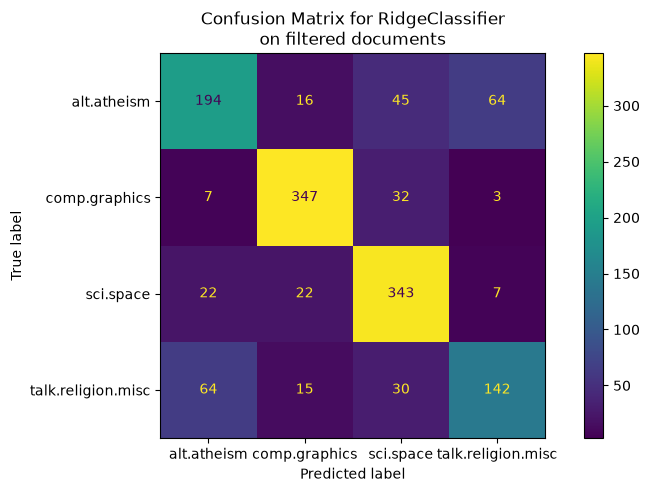

In [8]:
(
    X_train,
    X_test,
    y_train,
    y_test,
    feature_names,
    target_names,
) = load_dataset(remove=("headers", "footers", "quotes"))

clf = RidgeClassifier(tol=1e-2, solver="sparse_cg")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(
    f"Confusion Matrix for {clf.__class__.__name__}\non filtered documents"
)

By looking at the confusion matrix, it is more evident that the scores of the
model trained with metadata were over-optimistic. The classification problem
without access to the metadata is less accurate but more representative of the
intended text classification problem.



top 5 keywords per class:
  alt.atheism comp.graphics sci.space talk.religion.misc
0         don      graphics     space                god
1      people          file      like          christian
2         say        thanks      nasa              jesus
3    religion         image     orbit         christians
4        post          does    launch              wrong


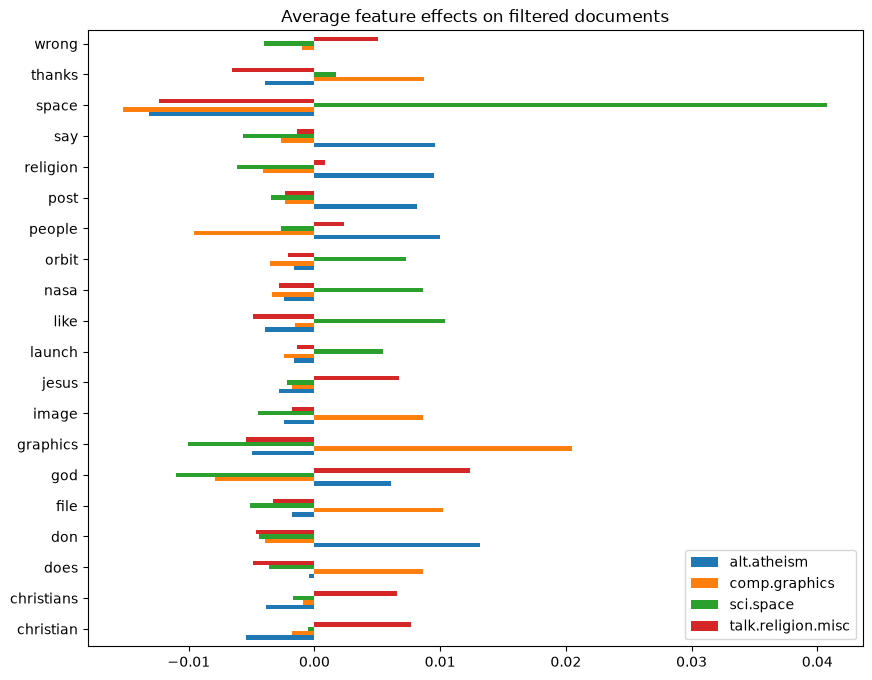

In [9]:
_ = plot_feature_effects().set_title("Average feature effects on filtered documents")

In the next section we keep the dataset without metadata to compare several
classifiers.



## Benchmarking classifiers

Scikit-learn provides many different kinds of classification algorithms. In
this section we will train a selection of those classifiers on the same text
classification problem and measure both their generalization performance
(accuracy on the test set) and their computation performance (speed), both at
training time and testing time. For such purpose we define the following
benchmarking utilities:



In [10]:
from sklearn import metrics
from sklearn.utils.extmath import density


def benchmark(clf, custom_name=False):
    print("_" * 80)
    print("Training: ")
    print(clf)
    t0 = time()
    clf.fit(X_train, y_train)
    train_time = time() - t0
    print(f"train time: {train_time:.3}s")

    t0 = time()
    pred = clf.predict(X_test)
    test_time = time() - t0
    print(f"test time:  {test_time:.3}s")

    score = metrics.accuracy_score(y_test, pred)
    print(f"accuracy:   {score:.3}")

    if hasattr(clf, "coef_"):
        print(f"dimensionality: {clf.coef_.shape[1]}")
        print(f"density: {density(clf.coef_)}")
        print()

    print()
    if custom_name:
        clf_descr = str(custom_name)
    else:
        clf_descr = clf.__class__.__name__
    return clf_descr, score, train_time, test_time

We now train and test the datasets with 8 different classification models and
get performance results for each model. The goal of this study is to highlight
the computation/accuracy tradeoffs of different types of classifiers for
such a multi-class text classification problem.

Notice that the most important hyperparameters values were tuned using a grid
search procedure not shown in this notebook for the sake of simplicity. See
the example script
`sphx_glr_auto_examples_model_selection_plot_grid_search_text_feature_extraction.py`  # noqa: E501
for a demo on how such tuning can be done.



In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import LinearSVC

results = []
for clf, name in (
    (LogisticRegression(C=5, max_iter=1000), "Logistic Regression"),
    (RidgeClassifier(alpha=1.0, solver="sparse_cg"), "Ridge Classifier"),
    (KNeighborsClassifier(n_neighbors=100), "kNN"),
    (RandomForestClassifier(), "Random Forest"),
    # L2 penalty Linear SVC
    (LinearSVC(C=0.1, dual=False, max_iter=1000), "Linear SVC"),
    # L2 penalty Linear SGD
    (
        SGDClassifier(
            loss="log_loss", alpha=1e-4, n_iter_no_change=3, early_stopping=True
        ),
        "log-loss SGD",
    ),
    # NearestCentroid (aka Rocchio classifier)
    (NearestCentroid(), "NearestCentroid"),
    # Sparse naive Bayes classifier
    (ComplementNB(alpha=0.1), "Complement naive Bayes"),
):
    print("=" * 80)
    print(name)
    results.append(benchmark(clf, name))

Logistic Regression
________________________________________________________________________________
Training: 
LogisticRegression(C=5, max_iter=1000)
train time: 6.45s
test time:  0.00118s
accuracy:   0.772
dimensionality: 5316
density: 1.0


Ridge Classifier
________________________________________________________________________________
Training: 
RidgeClassifier(solver='sparse_cg')
train time: 0.102s
test time:  0.00115s
accuracy:   0.76
dimensionality: 5316
density: 1.0


kNN
________________________________________________________________________________
Training: 
KNeighborsClassifier(n_neighbors=100)
train time: 0.00155s
test time:  0.0493s
accuracy:   0.752

Random Forest
________________________________________________________________________________
Training: 
RandomForestClassifier()
train time: 1.33s
test time:  0.0511s
accuracy:   0.695

Linear SVC
________________________________________________________________________________
Training: 
LinearSVC(C=0.1, dual=False)
trai

## Plot accuracy, training and test time of each classifier

The scatter plots show the trade-off between the test accuracy and the
training and testing time of each classifier.



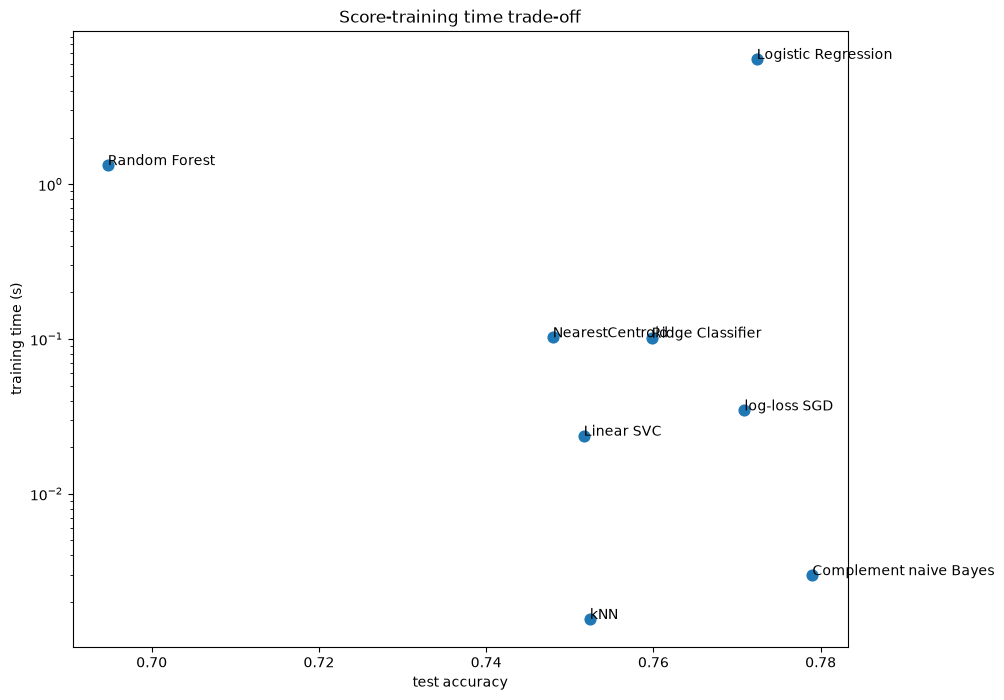

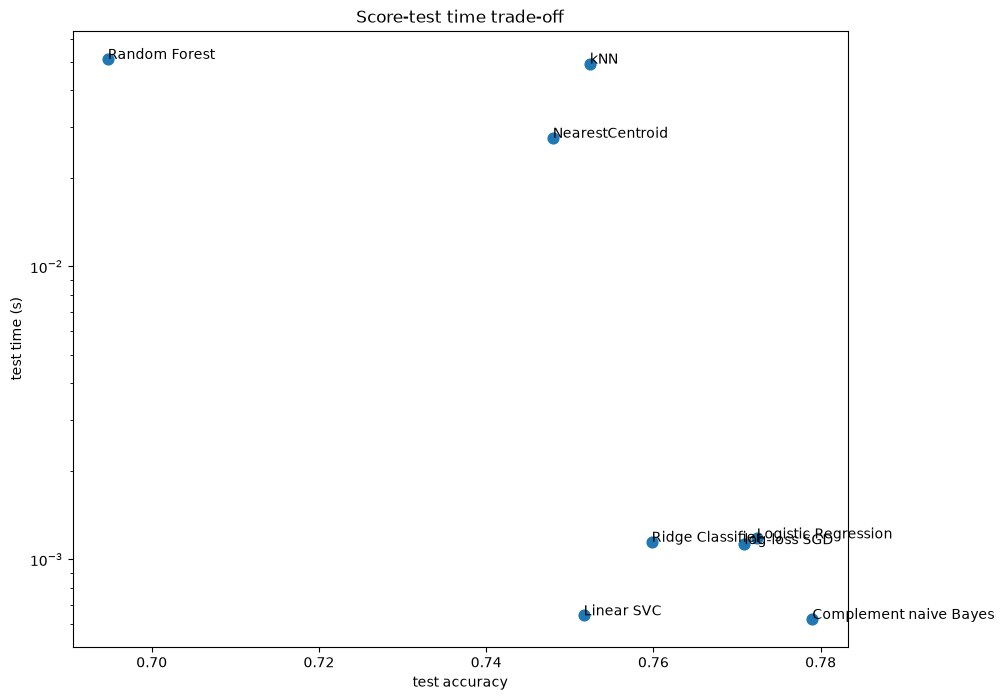

In [12]:
indices = np.arange(len(results))

results = [[x[i] for x in results] for i in range(4)]

clf_names, score, training_time, test_time = results
training_time = np.array(training_time)
test_time = np.array(test_time)

fig, ax1 = plt.subplots(figsize=(10, 8))
ax1.scatter(score, training_time, s=60)
ax1.set(
    title="Score-training time trade-off",
    yscale="log",
    xlabel="test accuracy",
    ylabel="training time (s)",
)
fig, ax2 = plt.subplots(figsize=(10, 8))
ax2.scatter(score, test_time, s=60)
ax2.set(
    title="Score-test time trade-off",
    yscale="log",
    xlabel="test accuracy",
    ylabel="test time (s)",
)

for i, txt in enumerate(clf_names):
    ax1.annotate(txt, (score[i], training_time[i]))
    ax2.annotate(txt, (score[i], test_time[i]))

The naive Bayes model has the best trade-off between score and
training/testing time, while Random Forest is both slow to train, expensive to
predict and has a comparatively bad accuracy. This is expected: for
high-dimensional prediction problems, linear models are often better suited as
most problems become linearly separable when the feature space has 10,000
dimensions or more.

The difference in training speed and accuracy of the linear models can be
explained by the choice of the loss function they optimize and the kind of
regularization they use. Be aware that some linear models with the same loss
but a different solver or regularization configuration may yield different
fitting times and test accuracy. We can observe on the second plot that once
trained, all linear models have approximately the same prediction speed which
is expected because they all implement the same prediction function.

KNeighborsClassifier has a relatively low accuracy and has the highest testing
time. The long prediction time is also expected: for each prediction the model
has to compute the pairwise distances between the testing sample and each
document in the training set, which is computationally expensive. Furthermore,
the "curse of dimensionality" harms the ability of this model to yield
competitive accuracy in the high dimensional feature space of text
classification problems.




TD3 : travail demandé (TO DO)

1. 

In [13]:
from time import perf_counter

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Graine de hasard unique : les résultats sont les mêmes à chaque exécution.
GRAINE = 42


def creer_classifieurs():
    """Renvoie la liste des classifieurs à comparer, sous forme (nom, modèle).

    Les réglages sont ceux de l'exemple de scikit-learn, pour pouvoir comparer.
    """
    return [
        ("Complement naive Bayes", ComplementNB(alpha=0.1)),
        ("Logistic Regression", LogisticRegression(C=5, max_iter=1000)),
        ("Linear SVC", LinearSVC(C=0.1, dual=False, max_iter=1000)),
        ("SVM (RBF kernel)", SVC(kernel="rbf", C=10)),
        ("Random Forest", RandomForestClassifier(random_state=GRAINE)),
        ("Decision Tree", DecisionTreeClassifier(random_state=GRAINE)),
    ]


def evaluer(nom, modele, X_app, y_app, X_eval, y_eval):
    """Entraîne un modèle, puis le teste sur des messages qu'il n'a jamais vus.

    Renvoie un dictionnaire avec l'accuracy, la F1 macro et le temps d'entraînement.
    """
    debut = perf_counter()
    modele.fit(X_app, y_app)                    # apprentissage
    duree = perf_counter() - debut
    prediction = modele.predict(X_eval)         # le modèle devine le sujet des messages de test
    return {
        "classifieur": nom,
        # part des messages bien classés
        "accuracy": metrics.accuracy_score(y_eval, prediction),
        # moyenne des F1 des 4 sujets : chaque sujet compte autant
        "F1 macro": metrics.f1_score(y_eval, prediction, average="macro"),
        "temps d'entraînement (s)": duree,
    }


resultats = pd.DataFrame(
    [evaluer(nom, modele, X_train, y_train, X_test, y_test) for nom, modele in creer_classifieurs()]
).sort_values("F1 macro", ascending=False, ignore_index=True)

print(resultats.round(3).to_string(index=False))

           classifieur  accuracy  F1 macro  temps d'entraînement (s)
Complement naive Bayes     0.779     0.759                     0.004
   Logistic Regression     0.772     0.751                     5.358
      SVM (RBF kernel)     0.746     0.723                     1.705
            Linear SVC     0.752     0.722                     0.098
         Random Forest     0.701     0.677                     1.516
         Decision Tree     0.592     0.578                     0.297


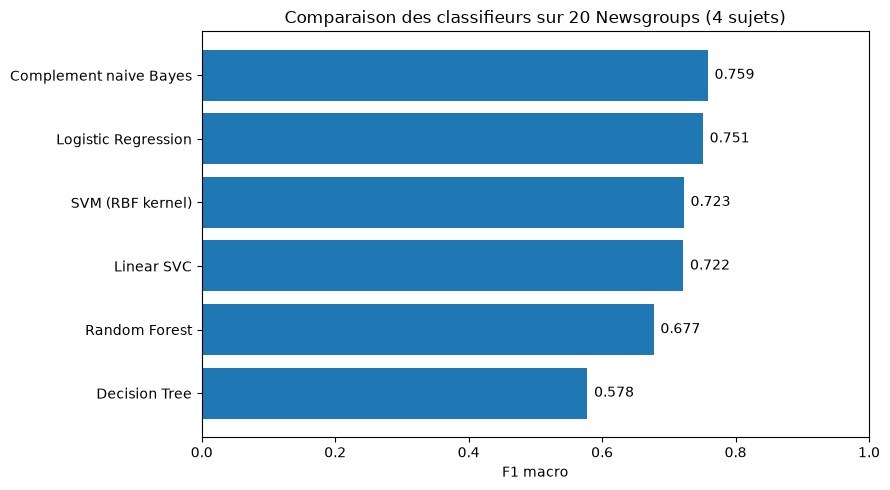

In [14]:
# Diagramme en barres : la F1 macro de chaque classifieur (plus la barre est longue, mieux c'est).
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(resultats["classifieur"], resultats["F1 macro"])
ax.invert_yaxis()                              # le meilleur classifieur en haut
ax.set_xlim(0, 1)
ax.set_xlabel("F1 macro")
ax.set_title("Comparaison des classifieurs sur 20 Newsgroups (4 sujets)")

# On écrit le score au bout de chaque barre.
for position, valeur in enumerate(resultats["F1 macro"]):
    ax.text(valeur + 0.01, position, f"{valeur:.3f}", va="center")

plt.tight_layout()
plt.savefig("fig7-comparaison-classifieurs.png", dpi=200, bbox_inches="tight")  # figure pour le rapport
plt.show()

**Commentaire :** Complement Naive Bayes est le meilleur classifieur (meilleure accuracy et meilleure F1 macro)
et aussi le plus rapide. La régression logistique est presque aussi bonne. Le SVM non linéaire (RBF) ne fait pas
mieux que le SVM linéaire et il est beaucoup plus lent. Les méthodes à base d'arbres sont les moins bonnes,
surtout l'arbre de décision seul : il décide mot par mot et apprend des règles trop précises, alors que les textes
contiennent des milliers de mots rares. Pour tous les modèles, la F1 macro est plus basse que l'accuracy :
au moins un sujet est plus difficile à reconnaître.

2.

In [15]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

# La LSA résume chaque message en 100 « thèmes » (groupes de mots qui vont ensemble).
# Normalizer remet ensuite tous les messages à la même échelle.
N_THEMES = 100
lsa = make_pipeline(TruncatedSVD(n_components=N_THEMES, random_state=GRAINE), Normalizer(copy=False))

# Les thèmes sont appris UNIQUEMENT sur les messages d'entraînement,
# puis on décrit les messages de test avec ces mêmes thèmes.
X_train_lsa = lsa.fit_transform(X_train)
X_test_lsa = lsa.transform(X_test)

# Part de l'information gardée par les 100 thèmes (variance expliquée).
variance_gardee = lsa.named_steps["truncatedsvd"].explained_variance_ratio_.sum()
print(f"Avant LSA : {X_train.shape[1]} mots | après LSA : {X_train_lsa.shape[1]} thèmes "
      f"({variance_gardee:.1%} de la variance gardée)")

# Naive Bayes est exclu : il n'accepte que des nombres positifs, et la LSA en produit des négatifs.
modeles_lsa = [
    ("Logistic Regression", LogisticRegression(C=5, max_iter=1000)),
    ("Linear SVC", LinearSVC(C=0.1, dual=False, max_iter=1000)),
    ("kNN", KNeighborsClassifier(n_neighbors=100)),
    ("Random Forest", RandomForestClassifier(random_state=GRAINE)),
    ("Decision Tree", DecisionTreeClassifier(random_state=GRAINE)),
]

lignes = []
for nom, modele in modeles_lsa:
    # Même modèle, testé deux fois : sur le TF-IDF complet, puis sur les 100 thèmes.
    sans_lsa = evaluer(nom, modele, X_train, y_train, X_test, y_test)["accuracy"]
    avec_lsa = evaluer(nom, modele, X_train_lsa, y_train, X_test_lsa, y_test)["accuracy"]
    lignes.append({"classifieur": nom, "TF-IDF": sans_lsa, "TF-IDF + LSA": avec_lsa,
                   "écart": avec_lsa - sans_lsa})

comparaison_lsa = pd.DataFrame(lignes)
print(comparaison_lsa.round(3).to_string(index=False))

Avant LSA : 5316 mots | après LSA : 100 thèmes (21.0% de la variance gardée)
        classifieur  TF-IDF  TF-IDF + LSA  écart
Logistic Regression   0.772         0.747 -0.025
         Linear SVC   0.752         0.749 -0.003
                kNN   0.752         0.717 -0.035
      Random Forest   0.701         0.728  0.027
      Decision Tree   0.592         0.693  0.101


**Commentaire :** la LSA améliore nettement les méthodes à base d'arbres (arbre de décision, forêt aléatoire),
car les 100 thèmes regroupent des mots proches. Elle fait en revanche légèrement baisser les modèles linéaires
et le kNN, qui perdent des informations sur des mots précis. Le meilleur résultat reste obtenu sans LSA.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# On recharge le TEXTE des messages d'entraînement filtrés (mêmes réglages que plus haut),
# car le Pipeline doit partir du texte pour réapprendre le TF-IDF dans chaque paquet.
textes_train = fetch_20newsgroups(
    subset="train", categories=categories, shuffle=True,
    random_state=42, remove=("headers", "footers", "quotes"),
).data


def pipeline_texte(modele):
    """TF-IDF (mêmes réglages que l'exemple) suivi du classifieur, dans une seule chaîne."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5, stop_words="english")),
        ("clf", modele),
    ])


# 5 paquets, avec la même proportion des 4 sujets dans chacun.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)

modeles_cv = [
    ("Complement naive Bayes", ComplementNB(alpha=0.1)),
    ("Logistic Regression", LogisticRegression(C=5, max_iter=1000)),
    ("Linear SVC", LinearSVC(C=0.1, dual=False, max_iter=1000)),
    ("Random Forest", RandomForestClassifier(random_state=GRAINE)),
    ("Decision Tree", DecisionTreeClassifier(random_state=GRAINE)),
]

lignes = []
for nom, modele in modeles_cv:
    scores = cross_val_score(pipeline_texte(modele), textes_train, y_train,
                             cv=cv, scoring="f1_macro", n_jobs=-1)
    lignes.append({"classifieur": nom,
                   "F1 macro moyenne": scores.mean(),
                   "écart-type": scores.std(),
                   "5 scores": scores.round(3)})

resultats_cv = pd.DataFrame(lignes).sort_values("F1 macro moyenne", ascending=False, ignore_index=True)
print(resultats_cv.round(3).to_string(index=False))

           classifieur  F1 macro moyenne  écart-type                            5 scores
   Logistic Regression             0.821       0.021 [0.814, 0.843, 0.789, 0.814, 0.843]
Complement naive Bayes             0.813       0.012 [0.813, 0.835, 0.799, 0.811, 0.805]
            Linear SVC             0.796       0.021   [0.8, 0.825, 0.758, 0.798, 0.799]
         Random Forest             0.729       0.026  [0.76, 0.747, 0.694, 0.742, 0.702]
         Decision Tree             0.579       0.026 [0.562, 0.559, 0.552, 0.616, 0.604]


**Commentaire :** la validation croisée permet de vérifier que le classement n'est pas dû au hasard d'un seul
découpage : un bon modèle a une moyenne élevée **et** un petit écart-type. On compare ensuite ces scores à ceux de
l'ensemble de test : ce dernier contient des messages **plus récents**, écrits après ceux de l'entraînement, ce qui
le rend en général un peu plus difficile. Le score de test reste donc le plus réaliste.

4.

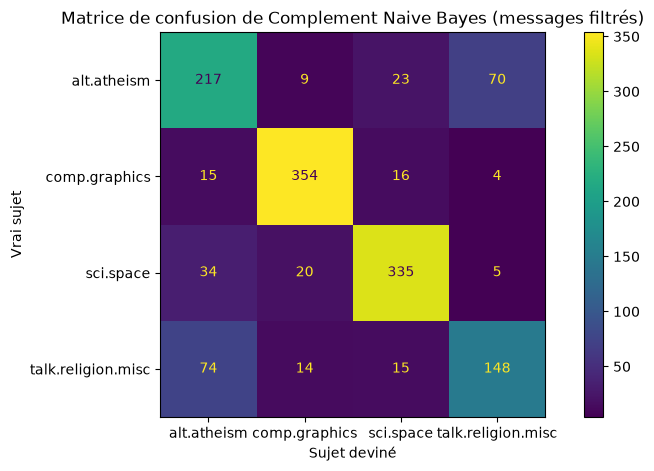

                    precision    recall  f1-score   support

       alt.atheism      0.638     0.680     0.659       319
     comp.graphics      0.892     0.910     0.901       389
         sci.space      0.861     0.850     0.856       394
talk.religion.misc      0.652     0.590     0.619       251

          accuracy                          0.779      1353
         macro avg      0.761     0.758     0.759      1353
      weighted avg      0.779     0.779     0.778      1353



In [17]:
# On réentraîne le meilleur modèle (Complement Naive Bayes) et on le teste.
meilleur_modele = ComplementNB(alpha=0.1).fit(X_train, y_train)
prediction_nb = meilleur_modele.predict(X_test)

# Matrice de confusion : une ligne = le vrai sujet, une colonne = le sujet deviné.
# La diagonale contient les bonnes réponses ; tout le reste, ce sont des erreurs.
fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, prediction_nb, display_labels=target_names, ax=ax)
ax.set_xlabel("Sujet deviné")
ax.set_ylabel("Vrai sujet")
ax.set_title("Matrice de confusion de Complement Naive Bayes (messages filtrés)")
plt.savefig("fig8-confusion-naive-bayes.png", dpi=200, bbox_inches="tight")  # figure pour le rapport
plt.show()

# Pour chaque sujet : précision, rappel et F1.
# - précision : quand le modèle annonce ce sujet, a-t-il raison ?
# - rappel : a-t-il retrouvé tous les messages de ce sujet ?
print(metrics.classification_report(y_test, prediction_nb, target_names=target_names, digits=3))

**Commentaire :** les sujets techniques (*comp.graphics*, *sci.space*) sont très bien reconnus.
L'erreur principale est la confusion entre *alt.atheism* et *talk.religion.misc*, dans les deux sens :
ces deux sujets parlent de religion avec les mêmes mots.

5. 

In [18]:
# On recharge le TEXTE des messages de test (mêmes réglages, donc même ordre que X_test),
# pour pouvoir lire les messages mal classés.
textes_test = fetch_20newsgroups(
    subset="test", categories=categories, shuffle=True,
    random_state=42, remove=("headers", "footers", "quotes"),
).data

erreurs = np.flatnonzero(prediction_nb != y_test)    # positions des messages mal classés
reussites = np.flatnonzero(prediction_nb == y_test)  # positions des messages bien classés
print(f"{len(erreurs)} erreurs sur {len(y_test)} messages de test ({len(erreurs) / len(y_test):.1%})")

# 1. Les erreurs sont-elles des messages plus courts ?
longueurs = np.array([len(texte.split()) for texte in textes_test])   # nombre de mots par message
print("Longueur médiane des messages bien classés :", np.median(longueurs[reussites]), "mots")
print("Longueur médiane des messages mal classés  :", np.median(longueurs[erreurs]), "mots")
print("Messages mal classés de moins de 20 mots   :", int((longueurs[erreurs] < 20).sum()))


# 2. Lire quelques erreurs pour les confusions les plus fréquentes.
def montrer_erreurs(vrai_sujet, sujet_devine, n=3, nb_caracteres=400):
    """Affiche le début de n messages d'un sujet donné, classés à tort dans un autre sujet."""
    vrai = target_names.index(vrai_sujet)
    devine = target_names.index(sujet_devine)
    positions = [i for i in erreurs if y_test[i] == vrai and prediction_nb[i] == devine]
    print("=" * 80)
    print(f"VRAI : {vrai_sujet}  ->  DEVINÉ : {sujet_devine}  ({len(positions)} messages)")
    for i in positions[:n]:
        print("-" * 80)
        print(textes_test[i][:nb_caracteres].strip() or "[message vide]")


montrer_erreurs("talk.religion.misc", "alt.atheism")
montrer_erreurs("alt.atheism", "talk.religion.misc")
montrer_erreurs("sci.space", "alt.atheism")

299 erreurs sur 1353 messages de test (22.1%)
Longueur médiane des messages bien classés : 90.0 mots
Longueur médiane des messages mal classés  : 52.0 mots
Messages mal classés de moins de 20 mots   : 76
VRAI : talk.religion.misc  ->  DEVINÉ : alt.atheism  (74 messages)
--------------------------------------------------------------------------------
This discussion on "objective" seems to be falling into solipsism (Eg: the
recent challenge from Frank Dwyer, for someone to prove that he can actually
observe phenomena).  Someones even made the statement that science is
"subjective" and that even atom are "subjective." This is getting a bit silly
and the word "objective" is losing all meaning.  Lets start by remembering the
definition of "object
--------------------------------------------------------------------------------
Hmm...are you a Taoist?  Imposing limits *does* do something useful...it gives
you something to go beyond.


I tend to be a bit critical of any stratification of Taoi

**Commentaire :** les messages mal classés sont nettement plus courts (peu de mots = peu d'indices).
La lecture des erreurs montre trois causes : *alt.atheism* et *talk.religion.misc* utilisent le même vocabulaire
(le modèle compte les mots mais ne comprend pas si l'auteur est pour ou contre la religion) ; certains messages sont
vides après la suppression des en-têtes et des citations ; d'autres sont hors sujet par rapport à leur forum.
Ces erreurs viennent autant des limites des données que de celles du modèle.

## Conclusion

Complement Naive Bayes est le meilleur modèle sur ces données : le plus précis, le plus rapide et le plus stable.
La LSA aide surtout les méthodes à base d'arbres. Aucun modèle ne sépare bien l'athéisme et la religion,
qui partagent le même vocabulaire ; il faudrait une représentation qui tienne compte du sens des phrases,
par exemple des modèles de langue récents.